# Pipeline de risque d'inondation sur route : V1 et V2

Ce notebook explique le pipeline de bout en bout : données → variables → V1 → V2 → évaluation → démonstration. Chaque résultat est suivi de son interprétation.

**Avertissement.** Les données sont synthétiques (`flood_risk/synth.py`). Les chiffres mesurent le fonctionnement du pipeline, pas la performance réelle du système (section 8 du cahier des charges).

```
synth.py → inventaire → features.py → v1.py / v2.py → train.py (évaluation) → predict.py
```

## 1. Données

Chaque ligne = un **segment de route** × un **orage** × un **créneau** (−60, −30, 0, +30 min autour du pic).

- `flooded` : inondation **documentée** (ce qu'on observe en pratique, presse et protection civile).
- `flooded_true` : vraie inondation, visible seulement en synthétique.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from flood_risk.schema import RAW_FEATURES, LABEL, LEVELS

inv = pd.read_csv("data/inventory_synthetic.csv")
print(f"{len(inv):,} lignes | {inv.event_id.nunique()} orages | {inv.segment_id.nunique()} segments")
print(f"inondations documentées : {inv[LABEL].mean():.2%}")
print(f"vraies inondations      : {inv['flooded_true'].mean():.2%}")
inv.head(3)

51,200 lignes | 16 orages | 800 segments
inondations documentées : 1.61%
vraies inondations      : 2.38%


,segment_id,x_km,y_km,elevation_rel_m,slope_pct,twi,depression_depth_m,dist_wadi_m,impervious_frac,drain_inlet_density,...,rain_1h_mm,rain_3h_mm,rain_24h_mm,dry_spell_days,rain_interpolated,data_age_min,event_id,slot_min,flooded_true,flooded
0,S00000,15.479121,14.771608,34.911682,6.002320,5.666143,0.433317,1237.196572,0.230793,13.0,...,0.052243,0.052251,4.799511,11.572217,1,90,E00,-60,0,0
1,S00001,8.777569,6.343063,19.050488,0.994546,5.736504,0.000000,1198.774820,0.508361,20.0,...,0.122211,0.122231,5.095896,11.572217,1,15,E00,-60,0,0
2,S00002,17.171958,17.800389,38.214225,1.562929,4.020863,0.000000,399.707971,0.057697,3.0,...,0.044528,0.044535,3.743637,11.572217,1,30,E00,-60,0,0


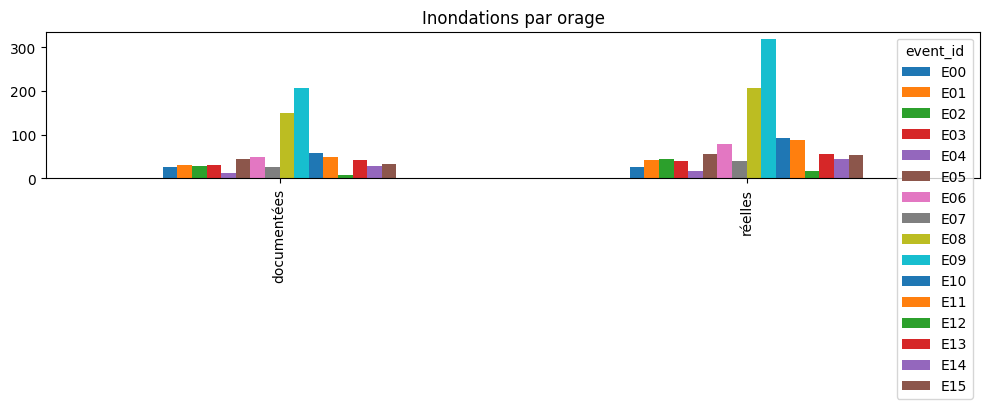

In [2]:
per_event = inv.groupby("event_id")[[LABEL, "flooded_true"]].sum()
per_event.columns = ["documentées", "réelles"]
per_event.T.plot.bar(figsize=(10, 3.2), title="Inondations par orage")
plt.tight_layout(); plt.show()

**Lecture.** Environ un tiers des inondations réelles n'est jamais documenté. C'est voulu : on reproduit le manque de données en Tunisie. Les inondations sont rares, donc l'exactitude (accuracy) serait trompeuse : on juge avec le **rappel**, le **taux de fausses alertes** et la **PR-AUC**.

In [3]:
inv[RAW_FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
elevation_rel_m,28.06,9.78,3.82,51.86
slope_pct,2.66,2.12,0.27,17.03
twi,5.56,1.70,2.00,12.98
depression_depth_m,0.07,0.23,0.00,2.43
dist_wadi_m,879.03,902.50,20.00,5000.00
impervious_frac,0.31,0.20,0.00,0.89
drain_inlet_density,6.85,6.79,0.00,34.00
osm_completeness,0.58,0.21,0.05,0.99
underpass,0.03,0.17,0.00,1.00
ford,0.04,0.18,0.00,1.00


**Lecture.** Les variables statiques (altitude, pente, wadi, béton) sont fixes par segment. Les variables de pluie changent à chaque créneau et à chaque orage.

## 2. Ingénierie des variables (`features.py`)

- `drainage_vulnerability` : proxy 0–1 du manque d'avaloirs (peu d'avaloirs OSM, saison sèche, béton, historique).
- `engineer` : variables combinées (ratio pluie / seuil effectif, ruissellement, pluie × proximité wadi, logarithmes).
- `MONOTONIC` : contraintes de monotonie pour le gradient boosting (plus de pluie ne peut pas réduire le risque).

count    51200.000
mean         0.434
std          0.136
min          0.131
25%          0.309
50%          0.424
75%          0.556
max          0.826
dtype: float64


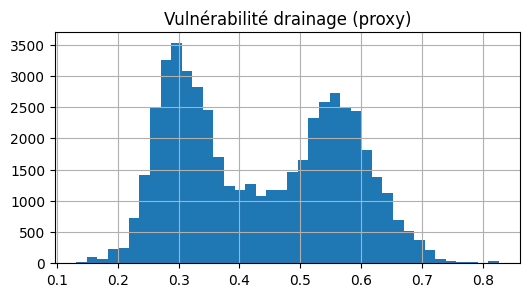

20 variables : ['elevation_rel_m', 'twi', 'depression_depth_m', 'impervious_frac', 'drain_inlet_density', 'osm_completeness', 'underpass', 'ford', 'black_spot_count', 'rain_eta_mmh', 'rain_1h_mm', 'rain_3h_mm', 'rain_24h_mm', 'dry_spell_days', 'drainage_vuln', 'rain_excess_ratio', 'runoff_index', 'wadi_rain', 'log_dist_wadi', 'log_slope']


In [4]:
from flood_risk.features import drainage_vulnerability, engineer, MONOTONIC

dv = drainage_vulnerability(inv)
print(dv.describe().round(3))
pd.Series(dv).hist(bins=40, figsize=(6, 3)); plt.title("Vulnérabilité drainage (proxy)"); plt.show()

X = engineer(inv)
print(f"{X.shape[1]} variables :", list(X.columns))

## 3. V1 : index pondéré (`v1.py`)

Référence sans apprentissage. Les poids sont **fixés à la main**, pas calibrés sur des données.

In [5]:
from flood_risk import v1

print(v1.WEIGHTS)
s1 = pd.Series(v1.score(inv))
print(s1.describe().round(1))

{'rain': 0.3, 'antecedent': 0.1, 'depression': 0.15, 'wadi': 0.12, 'drainage': 0.12, 'impervious': 0.08, 'history': 0.08, 'slope': 0.05}
count    51200.0
mean        19.7
std         20.4
min          0.0
25%          1.4
50%         11.0
75%         37.5
max         83.1
dtype: float64


**Lecture.** Le score V1 est compris entre 0 et 100. Il n'est pas une probabilité : c'est un classement relatif, et les seuils de niveau doivent être choisis à part.

## 4. V2 : entraînement (`v2.py`)

Étapes de `v2.fit` :
1. Validation croisée par orage pour obtenir des prédictions « hors échantillon ».
2. Calibration de ces prédictions (isotonique si ≥ 150 positifs, sinon Platt).
3. Choix des seuils Moderate / High / Very high sur ces prédictions calibrées (rappel cible 90 % / 70 % / 35 %).
4. Entraînement final sur tout le jeu de données.

Pour la démonstration, on ré-entraîne un modèle avec le même décalage de prévision que `train.py`.

In [6]:
from flood_risk import v2
from flood_risk.train import with_forecast_error

rng = np.random.default_rng(1)
train = with_forecast_error(inv, rng.uniform(0, 30, len(inv)), rng)
demo_model = v2.fit("hgb", train)

print("seuils (probabilité calibrée) :", {k: round(v, 3) for k, v in demo_model.thresholds.items()})
print("événements :", demo_model.trained_on["events"], "| positifs :", demo_model.trained_on["positives"])
print("variables  :", len(demo_model.columns))

seuils (probabilité calibrée) : {'Moderate': 0.007, 'High': 0.031, 'Very high': 0.191}
événements : 16 | positifs : 825
variables  : 20


**Lecture.** Les seuils sont très bas en valeur absolue (quelques pour cent) : c'est normal, car les inondations sont rares. Un segment classé **High** a donc une probabilité estimée de quelques pour cent seulement. C'est pour cela que le score affiché est ancré sur les niveaux et que la probabilité est montrée à côté.

In [7]:
import joblib

saved = joblib.load("models/v2_hgb.joblib")   # modèle produit par train.py
print("type       :", saved.kind)
print("seuils     :", {k: round(v, 4) for k, v in saved.thresholds.items()})
print("entraîné   :", saved.trained_on["trained_at"])

type       : hgb
seuils     : {'Moderate': 0.0068, 'High': 0.0308, 'Very high': 0.1912}
entraîné   : 2026-10-21T12:00:07+00:00


## 5. Évaluation : validation croisée par orage (`train.py`)

Protocole : 4 folds, un fold = 4 orages jamais vus à l'entraînement. Les prévisions sont dégradées selon le délai (0, 10, 20, 30 min). Les métriques sont mesurées contre les inondations **documentées**.

In [8]:
cv = pd.read_csv("reports/cv_metrics.csv")
COLS = ["recall_high", "false_alarm", "alerts_per_1000", "roc_auc", "pr_auc", "brier", "ece"]
ORDER = ["v1", "logistic", "hgb", "hgb_no_drainage"]

def table(target, lead=20):
    sub = cv[(cv.target == target) & (cv.lead == lead)]
    m = sub.groupby("model")[COLS].mean().loc[ORDER]
    s = sub.groupby("model")[COLS].std().loc[ORDER]
    return pd.DataFrame({c: m[c].round(3).astype(str) + " ± " + s[c].round(3).astype(str) for c in COLS})

print("Inondations documentées, délai 20 min")
table("flooded")

Inondations documentées, délai 20 min


,recall_high,false_alarm,alerts_per_1000,roc_auc,pr_auc,brier,ece
model,,,,,,,
v1,0.712 ± 0.169,0.934 ± 0.027,226.543 ± 221.556,0.846 ± 0.042,0.159 ± 0.063,0.015 ± 0.005,0.005 ± 0.002
logistic,0.704 ± 0.091,0.885 ± 0.037,112.051 ± 79.39,0.889 ± 0.015,0.262 ± 0.101,0.013 ± 0.006,0.005 ± 0.006
hgb,0.713 ± 0.07,0.895 ± 0.035,112.91 ± 43.695,0.896 ± 0.019,0.269 ± 0.096,0.013 ± 0.005,0.004 ± 0.001
hgb_no_drainage,0.703 ± 0.101,0.882 ± 0.038,101.016 ± 47.445,0.897 ± 0.021,0.27 ± 0.093,0.013 ± 0.005,0.004 ± 0.001


In [9]:
print("Niveau événement (segment × orage), délai 20 min")
table("event_level")

Niveau événement (segment × orage), délai 20 min


,recall_high,false_alarm,alerts_per_1000,roc_auc,pr_auc,brier,ece
model,,,,,,,
v1,0.809 ± 0.126,0.874 ± 0.031,374.453 ± 264.749,0.835 ± 0.041,0.278 ± 0.072,0.044 ± 0.016,0.024 ± 0.015
logistic,0.732 ± 0.089,0.792 ± 0.064,200.391 ± 118.484,0.875 ± 0.024,0.414 ± 0.137,0.038 ± 0.013,0.016 ± 0.004
hgb,0.756 ± 0.055,0.803 ± 0.06,207.578 ± 78.577,0.872 ± 0.029,0.416 ± 0.119,0.039 ± 0.013,0.02 ± 0.01
hgb_no_drainage,0.739 ± 0.077,0.785 ± 0.062,187.969 ± 82.704,0.874 ± 0.03,0.416 ± 0.12,0.038 ± 0.012,0.02 ± 0.008


In [10]:
lead = cv[cv.target == "flooded"].groupby(["model", "lead"])[["recall_high", "false_alarm", "pr_auc"]].mean()
lead.round(3).unstack("lead").loc[ORDER]

recall_high                      false_alarm                \
lead                     0      10     20     30          0      10     20   
model                                                                        
v1                    0.734  0.729  0.712  0.702       0.935  0.935  0.934   
logistic              0.705  0.705  0.704  0.681       0.884  0.884  0.885   
hgb                   0.722  0.722  0.713  0.693       0.895  0.894  0.895   
hgb_no_drainage       0.703  0.708  0.703  0.673       0.883  0.882  0.882   

                       pr_auc                       
lead                30     0      10     20     30  
model                                               
v1               0.933  0.157  0.165  0.159  0.153  
logistic         0.889  0.276  0.276  0.262  0.232  
hgb              0.895  0.275  0.278  0.269  0.245  
hgb_no_drainage  0.886  0.278  0.280  0.270  0.247

### Analyse des résultats

**1. V1 est un bon point de départ mais produit trop d'alertes.** Son rappel (≈ 0,71) est proche de V2, mais son taux de fausses alertes est ≈ 0,93 : sur 1000 alertes, environ 930 sont sans inondation. Sa PR-AUC est la plus basse (≈ 0,16), donc il classe mal les segments.

**2. V2 classe mieux, sans régler le problème des fausses alertes.** La PR-AUC passe de ≈ 0,16 à ≈ 0,27 et le rappel reste ≈ 0,71. Le taux de fausses alertes baisse un peu (≈ 0,90) et les alertes par 1000 passent de ≈ 227 à ≈ 113. Le gain est réel, mais l'objectif du cahier des charges (≤ 40 % de fausses alertes) n'est **pas** atteint.

**3. Le plafond théorique explique pourquoi.** En classant les segments avec la **vraie** probabilité cachée (l'oracle), le taux de fausses alertes à 70 % de rappel reste ≈ 0,83 contre les inondations documentées, et ≈ 0,71 contre toutes les inondations. Aucun modèle ne peut descendre sous ce niveau : une inondation est un tirage aléatoire même quand la probabilité est connue. Sur ces données, l'objectif de 40 % est donc hors d'atteinte à la granularité segment × créneau.

**4. Au niveau événement, le résultat est meilleur.** Un segment est jugé inondé s'il l'a été à un moment de l'orage. V2 atteint un rappel ≈ 0,75 avec une PR-AUC ≈ 0,42, contre ≈ 0,28 pour V1. C'est plus proche de la façon dont la presse et la protection civile datent les événements.

**5. La calibration est bonne.** ECE ≈ 0,004 pour V2 (contre ≈ 0,005 pour V1) et Brier plus bas. Quand le modèle annonce 10 %, la fréquence observée est proche de 10 % (voir la figure de fiabilité ci-dessous).

**6. Le délai de prévision a peu d'effet dans cette simulation.** Le rappel reste stable entre 0 et 30 min. Cela vient du modèle d'erreur choisi (erreur de prévision modérée). En réel, l'erreur sera plus grande : ce résultat n'est donc pas une preuve que le délai est sans importance.

**7. L'effet « drainage » n'est pas prouvé par l'ablation.** V2 sans les proxies drainage obtient la même PR-AUC (≈ 0,270 contre ≈ 0,269) et un taux de fausses alertes équivalent. Les proxies ne font donc pas mieux que le reste dans ces données. C'est l'hypothèse centrale du projet : elle doit être vérifiée sur des données réelles.

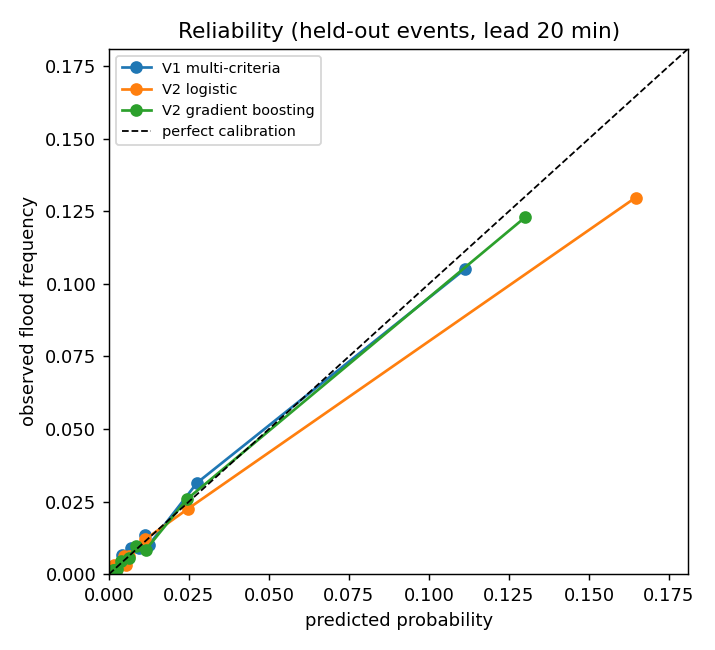

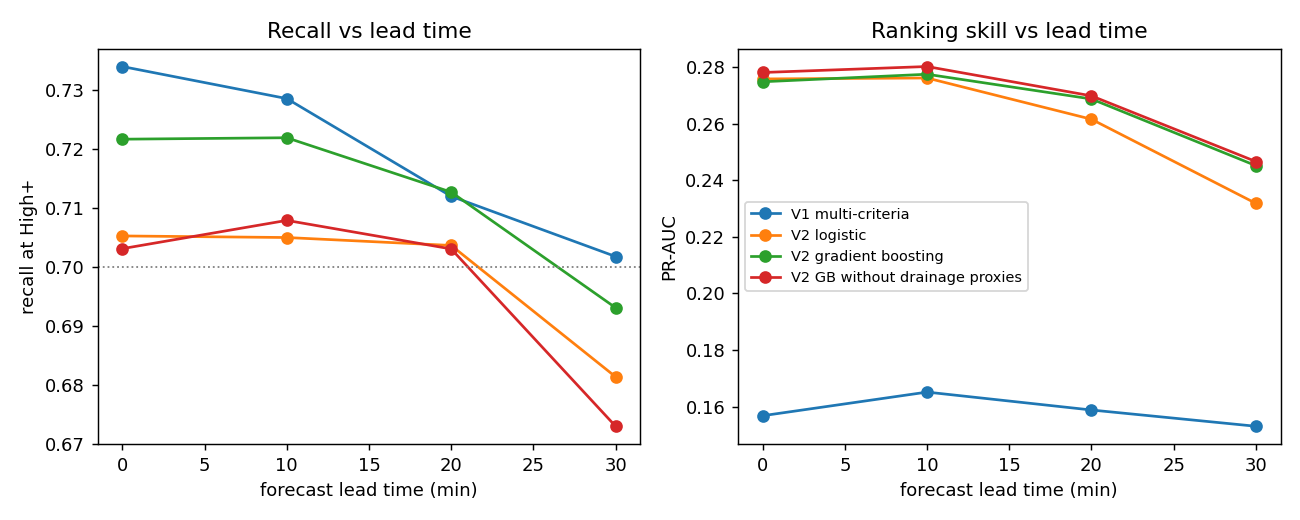

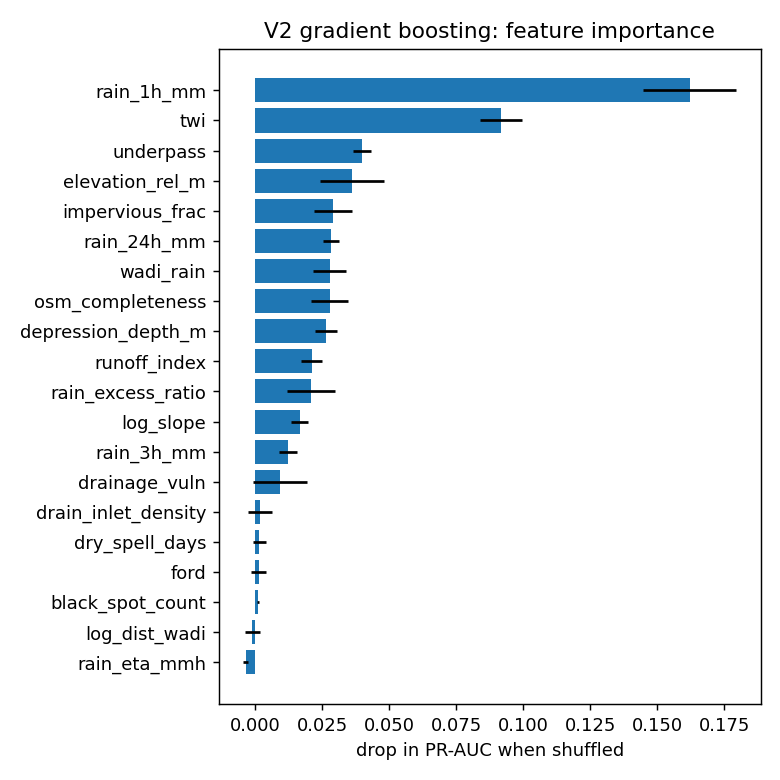

In [11]:
display(Image("reports/reliability.png", width=480))
display(Image("reports/lead_time.png", width=760))
display(Image("reports/importance.png", width=420))

**Lecture des figures.**
- **Fiabilité** : les points doivent suivre la diagonale. Ils la suivent de près : la calibration tient.
- **Délai** : courbes presque plates, pour la raison donnée au point 6.
- **Importance** : la pluie récente (`rain_1h_mm`) domine, puis la topographie (`twi`, dépression, altitude) et les passages sous-voie. Les variables de drainage ont une importance quasi nulle, ce qui renforce le point 7.

In [12]:
from flood_risk.train import drainage_effect, oracle_false_alarm

print("Test drainage (section 8) :")
print(drainage_effect(inv))
print()
print("Plafond oracle (fausses alertes à 70 % de rappel) :")
print(oracle_false_alarm(inv, "data/segments_synthetic.csv"))

Test drainage (section 8) :
{'n_high': 275, 'n_low': 275, 'median_rain_high': np.float64(14.861273842895937), 'median_rain_low': np.float64(40.54733277891276), 'p_value': np.float64(6.114005972568126e-26)}

Plafond oracle (fausses alertes à 70 % de rappel) :


{'flooded': np.float64(0.8304488119683191), 'flooded_true': np.float64(0.7065888812628689)}


**Lecture.** Le test drainage est très significatif (p ≈ 10⁻²⁵) : les segments à forte vulnérabilité drainage sont inondés à une pluie beaucoup plus faible. Mais ce test est **confondu** : ces segments sont aussi les plus bétonnés, et les routes bétonnées se remplissent vite quel que soit l'état des avaloirs. L'ablation ci-dessus est donc le test le plus fiable, et elle n'est pas concluante.

## 6. Démonstration : trajet de 25 min (`predict.py`)

Un trajet traverse la zone pendant un orage jamais vu à l'entraînement. Le modèle sauvegardé donne un score, un niveau, une probabilité, une confiance et les facteurs principaux pour chaque segment.

In [13]:
from flood_risk.predict import demo_route, score_route

route = demo_route(np.random.default_rng(7))
res = score_route(saved, route, "demo")

res["level"].value_counts().reindex(LEVELS, fill_value=0).to_frame("segments")

,segments
level,
Low,8
Moderate,10
High,15
Very high,0


In [14]:
cols = ["segment_id", "eta_min", "risk_score", "flood_prob_pct", "level", "confidence_level", "main_factors"]
res.sort_values("risk_score", ascending=False).head(10)[cols]

,segment_id,eta_min,risk_score,flood_prob_pct,level,confidence_level,main_factors
13,S00659,10.2,72,17.2,High,High,"rain already fallen (+14), forecast rainfall (..."
19,S00744,14.8,70,15.8,High,High,"forecast rainfall (+12), rain already fallen (..."
21,S00705,16.4,70,15.8,High,High,"rain already fallen (+12), impervious surface ..."
18,S00557,14.1,70,15.8,High,High,"rain already fallen (+12), forecast rainfall (..."
20,S00288,15.6,64,12.1,High,Medium,"forecast rainfall (+9), impervious surface (+9..."
23,S00772,18.0,64,12.1,High,Low,"rain already fallen (+9), forecast rainfall (+..."
25,S00492,19.5,59,8.9,High,Medium,"impervious surface (+8), forecast rainfall (+6..."
14,S00625,10.9,59,8.9,High,Medium,"rain already fallen (+6), forecast rainfall (+..."
11,S00493,8.6,59,8.9,High,High,"underpass (+7), forecast rainfall (+6), imperv..."
27,S00105,21.1,59,8.9,High,Medium,"rain already fallen (+8), forecast rainfall (+..."


**Lecture.** Le trajet compte 15 segments classés **High**, avec des probabilités estimées entre 3,1 et 17,2 %, et aucun segment **Very high** dans cette démonstration. C'est le compromis du modèle : rappel élevé, mais beaucoup de fausses alertes, comme vu en section 5. Les facteurs principaux (pluie récente, pluie prévue, imperméabilisation) sont cohérents avec la physique attendue. Le niveau **Very high** n'est atteint par aucun segment ici : son seuil (≈ 19 %) est élevé.

## 7. Limites et suites

- **Données** : tout est synthétique. Il faut des inondations documentées en Tunisie (Nabeul 2018, presse, protection civile) et des segments **non inondés** réels, avec la pluie historique.
- **Fausses alertes** : le taux reste au-dessus de l'objectif. Il faut soit accepter un objectif réaliste sur données réelles, soit baisser le niveau d'alerte, soit combiner plusieurs signaux (confiance, feedback utilisateurs).
- **Drainage** : aucune preuve encore. Les proxies doivent être testés sur des données de la municipalité ou de l'autorité de drainage.
- **Données spatiales** : les coordonnées sont à relier à PostGIS (table des segments) ; le modèle n'a besoin que des colonnes définies dans `flood_risk/schema.py`.